# 70 — TF-IDF + K-Means

Este notebook segue o fluxo dos experimentos 71, 72 e 73: configurar a análise, preparar os dados,
treinar os modelos, ordenar resultados, revisar clusters e avaliar uma taxonomia em uma reserva.
O ranking combina silhouette cosseno e cobertura da representação TF-IDF. Para K-Means, a fração
de vetores TF-IDF zerados funciona como proxy de ruído, pois o algoritmo atribui todos os itens.

A seleção final de categorias continua dependendo da revisão humana dos clusters.

In [1]:
import json
import logging
from pathlib import Path
from dataclasses import asdict
from datetime import datetime, timezone
from hashlib import sha256
from itertools import product
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, silhouette_score

from nofis_classifier.schema import DESCRIPTION_NORMALIZED, FREQUENCY
from nofis_classifier.tfidf import TfidfExperimentConfig
from nofis_classifier.clustering import (
    split_descriptions, load_local_model, inspect_documents, build_cluster_review,
    save_review_once, predict_categories,
)

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
logger = logging.getLogger("notebook70")
pd.set_option("display.max_colwidth", 160)


## 1. Parâmetros e matriz experimental

`word (1,1)` representa palavras; `word (1,2)` acrescenta pares de palavras;
`char_wb (3,5)` usa fragmentos de 3 a 5 caracteres dentro das palavras, com bordas.
`min_df` exige que o termo apareça em pelo menos esse número de descrições de treino.
`max_df` remove termos que aparecem em mais do que a proporção configurada das descrições de treino;
valores decimais representam proporções. `max_features` limita a quantidade de características do vocabulário.
A grade compara os valores configurados abaixo.

`k` é a quantidade de grupos solicitados. `n_init` escolhe a melhor inicialização por inércia
dentro de cada ajuste. As sementes configuradas mostram a variação das métricas; essa variação
não mede diretamente a concordância entre os agrupamentos.

`CONSIDER_FREQUENCY_IN_CLUSTERING` define se a frequência pondera o K-Means. Por padrão, fica False
e cada descrição única contribui uma vez. A frequência continua disponível para ordenar clusters
pelo volume e destacar descrições frequentes em clusters unitários. O vocabulário TF-IDF e as
métricas permanecem no nível de descrição única.

`TSNE_MAX_POINTS`, `TSNE_SVD_COMPONENTS`, `TSNE_PERPLEXITY`, `TSNE_MAX_ITER` e `TSNE_RANDOM_STATE`
controlam os PNGs t-SNE dos candidatos, gravados em suas pastas de revisão.

In [2]:
RUN_ID = None  # Opcional: informe um identificador unico para esta execucao.
DATASET_NAME = "2025_NCMs_filtrados-sem-duplicatas"  # Nome da pasta em data/processed.
PROJECT_ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "data" / "processed").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Nao encontrei a raiz do repositorio com data/processed/.")
DATASET_DIR = PROJECT_ROOT / "data" / "processed" / DATASET_NAME
DATASET_FILES = sorted(DATASET_DIR.glob("*.parquet"))
if not DATASET_FILES:
    raise FileNotFoundError(f"Nenhum Parquet encontrado para {DATASET_NAME}: {DATASET_DIR}")
if len(DATASET_FILES) > 1:
    raise ValueError(
        f"Mais de um Parquet encontrado em {DATASET_DIR}; selecione o arquivo/periodo explicitamente: "
        f"{[path.name for path in DATASET_FILES]}"
    )
DATASET_PATH = DATASET_FILES[0]
if not DATASET_PATH.stem.startswith(f"{DATASET_NAME}-"):
    raise ValueError(f"O nome do arquivo deve comecar com '{DATASET_NAME}-': {DATASET_PATH.name}")
PERIOD_LABEL = DATASET_PATH.stem[len(DATASET_NAME) + 1:]

MAX_DESCRIPTIONS = 5000  # None usa todas as descricoes; limite para ensaios rapidos.
CONSIDER_FREQUENCY_IN_CLUSTERING = False
VALIDATION_COUNT = 300
SPLIT_SEED = 42
REPRESENTATIONS = [
    ("word", (1, 1), [100_000]),
    ("word", (1, 2), [100_000]),
    ("char_wb", (3, 5), [100_000]),
]
MIN_DF_VALUES = [5]
MAX_DF_VALUES = [0.02]
K_VALUES = [20, 50, 100, 200]
SEEDS = [42]
N_INIT = 10
MAX_ITER = 300
METRIC_SAMPLE_SIZE = 1_000
SILHOUETTE_WEIGHT = 0.5
NOISE_WEIGHT = 0.5
TOP_COMBINATIONS = 3
TSNE_MAX_POINTS = 5_000
TSNE_SVD_COMPONENTS = 50
TSNE_PERPLEXITY = 30
TSNE_MAX_ITER = 1_000
TSNE_RANDOM_STATE = 42


In [3]:
configs = [
    TfidfExperimentConfig(
        name=f"{analyzer}_{ngrams[0]}_{ngrams[1]}_min{min_df}_maxdf{max_df:g}_features{max_features}",
        analyzer=analyzer, ngram_range=ngrams, min_df=min_df,
        max_df=max_df, max_features=max_features,
    )
    for analyzer, ngrams, feature_limits in REPRESENTATIONS
    for min_df, max_df, max_features in product(MIN_DF_VALUES, MAX_DF_VALUES, feature_limits)
]
experiment_matrix = pd.DataFrame([
    {**asdict(config), "k": k, "seed": seed, "n_init": N_INIT}
    for config, k, seed in product(configs, K_VALUES, SEEDS)
])
display(experiment_matrix)
logger.info("Grade planejada: %d ajustes", len(experiment_matrix))


,name,analyzer,ngram_range,min_df,max_features,max_df,sublinear_tf,norm,k,seed,n_init
0,word_1_1_min5_maxdf0.02_features100000,word,"(1, 1)",5,100000,0.02,True,l2,20,42,10
1,word_1_1_min5_maxdf0.02_features100000,word,"(1, 1)",5,100000,0.02,True,l2,50,42,10
2,word_1_1_min5_maxdf0.02_features100000,word,"(1, 1)",5,100000,0.02,True,l2,100,42,10
3,word_1_1_min5_maxdf0.02_features100000,word,"(1, 1)",5,100000,0.02,True,l2,200,42,10
4,word_1_2_min5_maxdf0.02_features100000,word,"(1, 2)",5,100000,0.02,True,l2,20,42,10
5,word_1_2_min5_maxdf0.02_features100000,word,"(1, 2)",5,100000,0.02,True,l2,50,42,10
6,word_1_2_min5_maxdf0.02_features100000,word,"(1, 2)",5,100000,0.02,True,l2,100,42,10
7,word_1_2_min5_maxdf0.02_features100000,word,"(1, 2)",5,100000,0.02,True,l2,200,42,10
8,char_wb_3_5_min5_maxdf0.02_features100000,char_wb,"(3, 5)",5,100000,0.02,True,l2,20,42,10
9,char_wb_3_5_min5_maxdf0.02_features100000,char_wb,"(3, 5)",5,100000,0.02,True,l2,50,42,10


2026-10-17 15:39:59,851 INFO Grade planejada: 12 ajustes


In [4]:
def compute_tsne_projection(frame, vectorizer, max_points, svd_components, perplexity, max_iter, random_state):
    """Calcula uma projecao t-SNE reproduzivel para uma amostra de descricoes."""
    if len(frame) < 3:
        raise ValueError("O t-SNE requer pelo menos tres descricoes.")
    if max_points < 3:
        raise ValueError("TSNE_MAX_POINTS deve ser pelo menos tres.")

    rng = np.random.default_rng(random_state)
    sample_positions = np.sort(rng.choice(len(frame), size=min(max_points, len(frame)), replace=False))
    texts = frame.iloc[sample_positions][DESCRIPTION_NORMALIZED]
    matrix = vectorizer.transform(texts)
    component_count = min(svd_components, matrix.shape[1] - 1, matrix.shape[0] - 1)
    if component_count < 2:
        raise ValueError("O t-SNE com SVD requer ao menos duas dimensoes TF-IDF.")

    reduced = TruncatedSVD(n_components=component_count, random_state=random_state).fit_transform(matrix)
    effective_perplexity = min(perplexity, len(sample_positions) - 1)
    coordinates = TSNE(
        n_components=2,
        perplexity=effective_perplexity,
        init="pca",
        learning_rate="auto",
        max_iter=max_iter,
        random_state=random_state,
    ).fit_transform(reduced)
    return sample_positions, coordinates


def save_candidate_tsne_plot(coordinates, cluster_labels, experiment_id, output_path):
    """Salva um PNG t-SNE colorido pelos clusters K-Means do candidato."""
    fig, axis = plt.subplots(figsize=(12, 9))
    points = axis.scatter(
        coordinates[:, 0], coordinates[:, 1], c=cluster_labels,
        cmap="turbo", s=9, alpha=0.75, linewidths=0,
    )
    fig.colorbar(points, ax=axis, label="Cluster K-Means")
    axis.set_title(f"t-SNE: {experiment_id}")
    axis.set_xlabel("t-SNE 1")
    axis.set_ylabel("t-SNE 2")
    fig.tight_layout()
    fig.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.close(fig)



## 2. Dados, reserva de validação e identificação da execução

A divisão ocorre por descrição normalizada única **antes de ajustar o vocabulário**.
As descrições reservadas não participam do TF-IDF, do K-Means nem do ranking.
Essa reserva aleatória avalia descrições não vistas da mesma base; não demonstra generalização
para meses futuros. A quantidade de treino será o total disponível menos a reserva.

Cada execução recebe um identificador e pastas próprias para relatórios e modelos. Os dados de
origem e os artefatos de execuções anteriores são preservados.

In [5]:
items = pd.read_parquet(DATASET_PATH)
required_columns = [DESCRIPTION_NORMALIZED, FREQUENCY]
missing_columns = set(required_columns) - set(items.columns)
if missing_columns:
    raise ValueError(f"Colunas ausentes no dataset: {sorted(missing_columns)}")
initial_frequency_sum = items[FREQUENCY].sum()
items[DESCRIPTION_NORMALIZED] = items[DESCRIPTION_NORMALIZED].astype("string").str.strip()
items = items[items[DESCRIPTION_NORMALIZED].notna() & items[DESCRIPTION_NORMALIZED].ne("")]
items = items[items[FREQUENCY] >= 1].copy()
items = items.groupby(DESCRIPTION_NORMALIZED, as_index=False, sort=False)[FREQUENCY].sum()
if items[FREQUENCY].sum() != initial_frequency_sum:
    raise ValueError("A preparacao alterou a soma de frequencia.")
items = items.sort_values(DESCRIPTION_NORMALIZED).reset_index(drop=True)
items.insert(0, "descricao_id", np.arange(len(items), dtype=np.int64))
if MAX_DESCRIPTIONS is not None:
    items = items.sample(n=min(MAX_DESCRIPTIONS, len(items)), random_state=SPLIT_SEED).reset_index(drop=True)
train, validation = split_descriptions(items, VALIDATION_COUNT, SPLIT_SEED)
assert set(train[DESCRIPTION_NORMALIZED]).isdisjoint(validation[DESCRIPTION_NORMALIZED])
assert all(2 <= k < len(train) for k in K_VALUES), "Reduza K_VALUES para esta base."

RUN_ID = RUN_ID or datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8]
assert all(character.isalnum() or character in "_-" for character in RUN_ID), "RUN_ID invalido"
REPORT_DIR = Path("reports/tfidf_kmeans") / f"{PERIOD_LABEL}_{RUN_ID}"
MODEL_DIR = Path("models/tfidf_kmeans") / f"{PERIOD_LABEL}_{RUN_ID}"
REPORT_DIR.mkdir(parents=True, exist_ok=False)
MODEL_DIR.mkdir(parents=True, exist_ok=False)

run_metadata = {
    "run_id": RUN_ID, "dataset": DATASET_NAME, "period": PERIOD_LABEL,
    "frequency_weighted": CONSIDER_FREQUENCY_IN_CLUSTERING,
    "dataset_sha256": sha256(pd.util.hash_pandas_object(items, index=True).values.tobytes()).hexdigest(),
    "validation_count": VALIDATION_COUNT, "split_seed": SPLIT_SEED,
    "max_descriptions": MAX_DESCRIPTIONS,
}
metadata_path = REPORT_DIR / "run.json"
if metadata_path.exists():
    if json.loads(metadata_path.read_text(encoding="utf-8")) != run_metadata:
        raise ValueError("A base ou a divisao mudou; use outro RUN_ID.")
else:
    metadata_path.write_text(json.dumps(run_metadata, indent=2, ensure_ascii=False), encoding="utf-8")
save_review_once(train, REPORT_DIR / "training_descriptions.csv")
save_review_once(validation, REPORT_DIR / "heldout_descriptions.csv")
experiment_matrix.to_csv(REPORT_DIR / "planned_grid.csv", index=False)
logger.info("RUN_ID: %s | Relatorios: %s", RUN_ID, REPORT_DIR)
display(pd.DataFrame({"particao": ["treino", "validacao"],
                      "descricoes": [len(train), len(validation)],
                      "frequencia_total": [train[FREQUENCY].sum(), validation[FREQUENCY].sum()]}))


2026-10-17 15:40:00,530 INFO RUN_ID: 20261017T184000Z_3881350d | Relatorios: reports\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d


,particao,descricoes,frequencia_total
0,treino,4700,25366
1,validacao,300,1940


## 3. Vetorizar, treinar e salvar cada resultado

Esta célula ajusta um TF-IDF por representação e reutiliza a matriz para todos os valores de k.
O K-Means é treinado nas descrições de treino; silhouette cosseno é calculada na mesma amostra
reprodutível para toda a grade. Modelos, métricas e vetorizadores são salvos na pasta da execução.

K-Means atribui todo item a um grupo e não marca ruído. Para compor o ranking com a mesma ideia
usada nos experimentos DBSCAN, `noise_fraction` representa aqui a fração de descrições cujo vetor
TF-IDF ficou zerado por não conter termos do vocabulário. Esses itens não têm sinal textual para
separação. A métrica é um proxy de cobertura da representação, não ruído produzido pelo K-Means.

In [6]:
if SILHOUETTE_WEIGHT < 0 or NOISE_WEIGHT < 0 or SILHOUETTE_WEIGHT + NOISE_WEIGHT <= 0:
    raise ValueError("Os pesos devem ser nao negativos e pelo menos um deve ser maior que zero.")

metric_rng = np.random.default_rng(SPLIT_SEED)
metric_positions = np.sort(metric_rng.choice(
    len(train), size=min(METRIC_SAMPLE_SIZE, len(train)), replace=False
))
train_texts = train[DESCRIPTION_NORMALIZED].astype(str)
records = []

for config in configs:
    logger.info("Ajustando TF-IDF: %s", config.name)
    vectorizer_path = MODEL_DIR / f"{config.name}_vectorizer.pkl"
    vectorizer = TfidfVectorizer(
        analyzer=config.analyzer, ngram_range=config.ngram_range,
        min_df=config.min_df, max_df=config.max_df,
        max_features=config.max_features, sublinear_tf=True, norm="l2",
    )
    matrix = vectorizer.fit_transform(train_texts)
    zero_vector_fraction = float((matrix.getnnz(axis=1) == 0).mean())
    pd.to_pickle(vectorizer, vectorizer_path)
    metric_matrix = matrix[metric_positions]
    logger.info("%s: %d termos; %.2f%% vetores zerados", config.name,
                matrix.shape[1], zero_vector_fraction * 100)

    for k, seed in product(K_VALUES, SEEDS):
        experiment_id = f"{config.name}_k{k}_seed{seed}"
        model_path = MODEL_DIR / f"{experiment_id}.pkl"
        logger.info("Ajustando K-Means: %s", experiment_id)
        model = KMeans(n_clusters=k, random_state=seed, n_init=N_INIT,
                       max_iter=MAX_ITER, algorithm="lloyd")
        sample_weight = train[FREQUENCY].to_numpy(dtype=float) if CONSIDER_FREQUENCY_IN_CLUSTERING else None
        model.fit(matrix, sample_weight=sample_weight)
        sample_labels = model.labels_[metric_positions]
        sample_cluster_count = len(np.unique(sample_labels))
        silhouette = (
            float(silhouette_score(metric_matrix, sample_labels, metric="cosine"))
            if 2 <= sample_cluster_count < len(metric_positions) else np.nan
        )
        counts = np.bincount(model.labels_, minlength=k)
        pd.to_pickle(model, model_path)
        records.append({
            "experiment_id": experiment_id, "config_name": config.name,
            "k": k, "seed": seed,
            "frequency_weighted": CONSIDER_FREQUENCY_IN_CLUSTERING,
            "feature_count": matrix.shape[1],
            "zero_vector_fraction": zero_vector_fraction,
            "noise_fraction": zero_vector_fraction,
            "silhouette_cosine": silhouette,
            "largest_cluster_fraction": float(counts.max() / len(train)),
            "sample_clusters": sample_cluster_count,
            "model_path": str(model_path), "vectorizer_path": str(vectorizer_path),
            "status": "ok",
        })

metrics = pd.DataFrame(records)
metrics.to_csv(REPORT_DIR / "metrics.csv", index=False)
display(metrics)


2026-10-17 15:40:00,573 INFO Ajustando TF-IDF: word_1_1_min5_maxdf0.02_features100000
2026-10-17 15:40:00,687 INFO word_1_1_min5_maxdf0.02_features100000: 1011 termos; 3.47% vetores zerados
2026-10-17 15:40:00,687 INFO Ajustando K-Means: word_1_1_min5_maxdf0.02_features100000_k20_seed42
2026-10-17 15:40:03,251 INFO Ajustando K-Means: word_1_1_min5_maxdf0.02_features100000_k50_seed42
2026-10-17 15:40:03,904 INFO Ajustando K-Means: word_1_1_min5_maxdf0.02_features100000_k100_seed42
2026-10-17 15:40:05,606 INFO Ajustando K-Means: word_1_1_min5_maxdf0.02_features100000_k200_seed42
2026-10-17 15:40:08,121 INFO Ajustando TF-IDF: word_1_2_min5_maxdf0.02_features100000
2026-10-17 15:40:08,303 INFO word_1_2_min5_maxdf0.02_features100000: 1327 termos; 3.21% vetores zerados
2026-10-17 15:40:08,304 INFO Ajustando K-Means: word_1_2_min5_maxdf0.02_features100000_k20_seed42
2026-10-17 15:40:08,675 INFO Ajustando K-Means: word_1_2_min5_maxdf0.02_features100000_k50_seed42
2026-10-17 15:40:09,831 INFO A

,experiment_id,config_name,k,seed,frequency_weighted,feature_count,zero_vector_fraction,noise_fraction,silhouette_cosine,largest_cluster_fraction,sample_clusters,model_path,vectorizer_path,status
0,word_1_1_min5_maxdf0.02_features100000_k20_seed42,word_1_1_min5_maxdf0.02_features100000,20,42,False,1011,0.034681,0.034681,0.038198,0.674681,20,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\word_1_1_min5_maxdf0.02_features100000_k20_seed42.pkl,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\word_1_1_min5_maxdf0.02_features100000_vectorizer.pkl,ok
1,word_1_1_min5_maxdf0.02_features100000_k50_seed42,word_1_1_min5_maxdf0.02_features100000,50,42,False,1011,0.034681,0.034681,0.063416,0.658298,48,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\word_1_1_min5_maxdf0.02_features100000_k50_seed42.pkl,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\word_1_1_min5_maxdf0.02_features100000_vectorizer.pkl,ok
2,word_1_1_min5_maxdf0.02_features100000_k100_seed42,word_1_1_min5_maxdf0.02_features100000,100,42,False,1011,0.034681,0.034681,0.089933,0.457660,96,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\word_1_1_min5_maxdf0.02_features100000_k100_seed42.pkl,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\word_1_1_min5_maxdf0.02_features100000_vectorizer.pkl,ok
3,word_1_1_min5_maxdf0.02_features100000_k200_seed42,word_1_1_min5_maxdf0.02_features100000,200,42,False,1011,0.034681,0.034681,0.124302,0.254894,182,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\word_1_1_min5_maxdf0.02_features100000_k200_seed42.pkl,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\word_1_1_min5_maxdf0.02_features100000_vectorizer.pkl,ok
4,word_1_2_min5_maxdf0.02_features100000_k20_seed42,word_1_2_min5_maxdf0.02_features100000,20,42,False,1327,0.032128,0.032128,0.034211,0.637447,20,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\word_1_2_min5_maxdf0.02_features100000_k20_seed42.pkl,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\word_1_2_min5_maxdf0.02_features100000_vectorizer.pkl,ok
5,word_1_2_min5_maxdf0.02_features100000_k50_seed42,word_1_2_min5_maxdf0.02_features100000,50,42,False,1327,0.032128,0.032128,0.056576,0.678723,49,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\word_1_2_min5_maxdf0.02_features100000_k50_seed42.pkl,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\word_1_2_min5_maxdf0.02_features100000_vectorizer.pkl,ok
6,word_1_2_min5_maxdf0.02_features100000_k100_seed42,word_1_2_min5_maxdf0.02_features100000,100,42,False,1327,0.032128,0.032128,0.074673,0.503404,96,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\word_1_2_min5_maxdf0.02_features100000_k100_seed42.pkl,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\word_1_2_min5_maxdf0.02_features100000_vectorizer.pkl,ok
7,word_1_2_min5_maxdf0.02_features100000_k200_seed42,word_1_2_min5_maxdf0.02_features100000,200,42,False,1327,0.032128,0.032128,0.123708,0.314255,186,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\word_1_2_min5_maxdf0.02_features100000_k200_seed42.pkl,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\word_1_2_min5_maxdf0.02_features100000_vectorizer.pkl,ok
8,char_wb_3_5_min5_maxdf0.02_features100000_k20_seed42,char_wb_3_5_min5_maxdf0.02_features100000,20,42,False,9592,0.000213,0.000213,0.035338,0.610851,20,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\char_wb_3_5_min5_maxdf0.02_features100000_k20_seed42.pkl,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\char_wb_3_5_min5_maxdf0.02_features100000_vectorizer.pkl,ok
9,char_wb_3_5_min5_maxdf0.02_features100000_k50_seed42,char_wb_3_5_min5_maxdf0.02_features100000,50,42,False,9592,0.000213,0.000213,0.070839,0.414255,50,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\char_wb_3_5_min5_maxdf0.02_features100000_k50_seed42.pkl,models\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\char_wb_3_5_min5_maxdf0.02_features100000_vect

### Quantidade de termos por representacao

A tabela conta as caracteristicas efetivamente aprendidas por configuracao, apos os filtros `min_df` e `max_df` e o limite `max_features`. Em `word`, sao palavras ou palavras e bigramas; em `char_wb`, sao fragmentos de caracteres. Cada contagem usa o vetorizar treinado apenas com as descricoes de treino.


In [7]:
vectorizer_counts = (
    metrics.loc[metrics["status"].eq("ok"), ["config_name", "vectorizer_path"]]
    .drop_duplicates("config_name")
    .sort_values("config_name")
)
vectorizer_counts["termos_no_vocabulario"] = [
    len(load_local_model(path).vocabulary_)
    for path in vectorizer_counts["vectorizer_path"]
]
display(vectorizer_counts[["config_name", "termos_no_vocabulario"]].reset_index(drop=True))


,config_name,termos_no_vocabulario
0,char_wb_3_5_min5_maxdf0.02_features100000,9592
1,word_1_1_min5_maxdf0.02_features100000,1011
2,word_1_2_min5_maxdf0.02_features100000,1327


## 4. Comparar silhouette e cobertura e selecionar candidatos

O ranking ordena as combinações por uma pontuação composta com pesos ajustáveis no início:
Silhouette cosseno reescalada para 0–1 e cobertura TF-IDF (1 − fração de vetores zerados).
Empates são ordenados por maior silhouette e menor fração de vetores zerados. O ranking usa as
medianas entre sementes; combinações sem silhouette definida ou sem todas as sementes são excluídas.

A fração de vetores zerados é apenas um proxy de ruído para TF-IDF + K-Means. Silhouette mede
separação interna e não é acurácia. As métricas em espaços de representação diferentes são
exploratórias. Os candidatos são as combinações mais bem colocadas; a decisão final depende da
revisão humana dos clusters.

In [8]:
metrics = pd.read_csv(REPORT_DIR / "metrics.csv")
metrics["silhouette_quality"] = (metrics["silhouette_cosine"] + 1) / 2
metrics["noise_quality"] = 1 - metrics["noise_fraction"]
weight_total = SILHOUETTE_WEIGHT + NOISE_WEIGHT
metrics["composite_score"] = (
    SILHOUETTE_WEIGHT * metrics["silhouette_quality"]
    + NOISE_WEIGHT * metrics["noise_quality"]
) / weight_total

ranking = metrics.groupby(["config_name", "k"], as_index=False).agg(
    silhouette_median=("silhouette_cosine", "median"),
    silhouette_std=("silhouette_cosine", "std"),
    noise_fraction_median=("noise_fraction", "median"),
    composite_score_median=("composite_score", "median"),
    largest_cluster_fraction=("largest_cluster_fraction", "median"),
    seed_count=("seed", "nunique"),
)
ranking = ranking[
    ranking.seed_count.eq(len(SEEDS)) & ranking.silhouette_median.notna()
].sort_values(
    ["composite_score_median", "silhouette_median", "noise_fraction_median"],
    ascending=[False, False, True], na_position="last",
).reset_index(drop=True)
if ranking.empty:
    raise RuntimeError("Nenhuma combinacao elegivel; verifique a grade e a silhouette.")
ranking.insert(0, "rank", range(1, len(ranking) + 1))
ranking.to_csv(REPORT_DIR / "ranking.csv", index=False)
display(ranking)

candidate_ids = []
for row in ranking.head(TOP_COMBINATIONS).itertuples(index=False):
    group = metrics[metrics.config_name.eq(row.config_name) & metrics.k.eq(row.k)].copy()
    median_score = group.composite_score.median()
    representative = group.loc[(group.composite_score - median_score).abs().idxmin()]
    candidate_ids.append(representative.experiment_id)
candidates = metrics.set_index("experiment_id").loc[candidate_ids].reset_index()
candidates.to_csv(REPORT_DIR / "candidates.csv", index=False)
display(candidates[["experiment_id", "silhouette_cosine", "noise_fraction",
                    "composite_score", "largest_cluster_fraction"]])


,rank,config_name,k,silhouette_median,silhouette_std,noise_fraction_median,composite_score_median,largest_cluster_fraction,seed_count
0,1,char_wb_3_5_min5_maxdf0.02_features100000,200,0.141113,NaN,0.000213,0.785172,0.154255,1
1,2,char_wb_3_5_min5_maxdf0.02_features100000,100,0.117610,NaN,0.000213,0.779296,0.243404,1
2,3,char_wb_3_5_min5_maxdf0.02_features100000,50,0.070839,NaN,0.000213,0.767603,0.414255,1
3,4,word_1_2_min5_maxdf0.02_features100000,200,0.123708,NaN,0.032128,0.764863,0.314255,1
4,5,word_1_1_min5_maxdf0.02_features100000,200,0.124302,NaN,0.034681,0.763735,0.254894,1
5,6,char_wb_3_5_min5_maxdf0.02_features100000,20,0.035338,NaN,0.000213,0.758728,0.610851,1
6,7,word_1_1_min5_maxdf0.02_features100000,100,0.089933,NaN,0.034681,0.755143,0.457660,1
7,8,word_1_2_min5_maxdf0.02_features100000,100,0.074673,NaN,0.032128,0.752604,0.503404,1
8,9,word_1_1_min5_maxdf0.02_features100000,50,0.063416,NaN,0.034681,0.748513,0.658298,1
9,10,word_1_2_min5_maxdf0.02_features100000,50,0.056576,NaN,0.032128,0.748080,0.678723,1


,experiment_id,silhouette_cosine,noise_fraction,composite_score,largest_cluster_fraction
0,char_wb_3_5_min5_maxdf0.02_features100000_k200_seed42,0.141113,0.000213,0.785172,0.154255
1,char_wb_3_5_min5_maxdf0.02_features100000_k100_seed42,0.117610,0.000213,0.779296,0.243404
2,char_wb_3_5_min5_maxdf0.02_features100000_k50_seed42,0.070839,0.000213,0.767603,0.414255


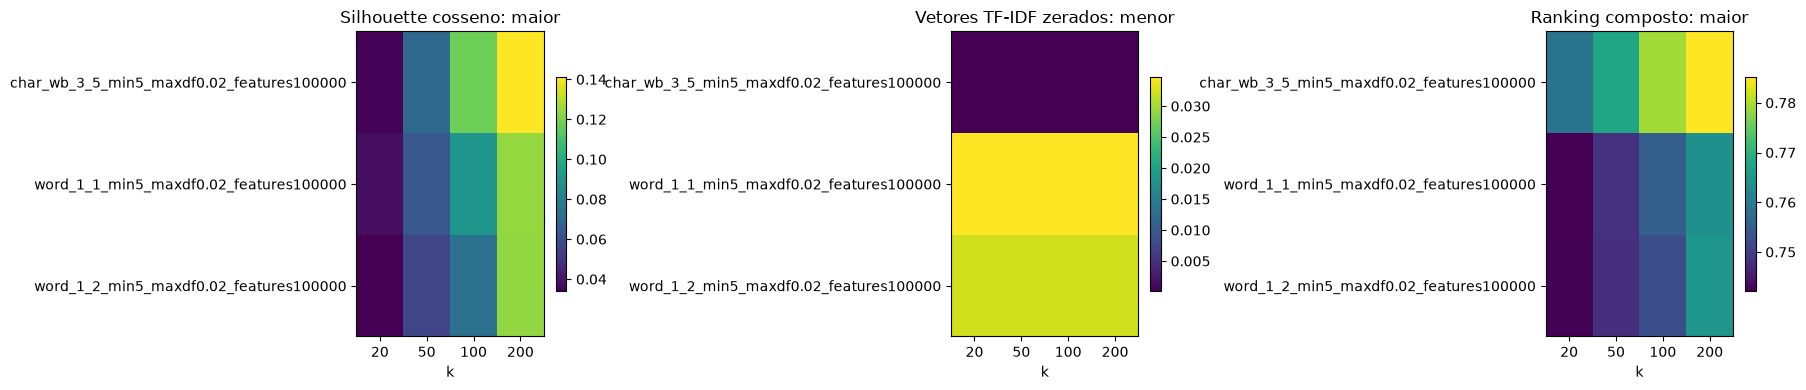

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, max(4, len(configs) * 0.6)))
for ax, metric, title in zip(
    axes,
    ["silhouette_median", "noise_fraction_median", "composite_score_median"],
    ["Silhouette cosseno: maior", "Vetores TF-IDF zerados: menor", "Ranking composto: maior"],
):
    table = ranking.pivot(index="config_name", columns="k", values=metric)
    plot = ax.imshow(np.ma.masked_invalid(table.to_numpy(dtype=float)), aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(table.columns)), table.columns)
    ax.set_yticks(range(len(table.index)), table.index)
    ax.set_xlabel("k")
    ax.set_title(title)
    fig.colorbar(plot, ax=ax, shrink=0.7)
fig.tight_layout()
fig.savefig(REPORT_DIR / "ranking_metrics.png", dpi=140, bbox_inches="tight")
plt.show()


## 5. Entender dez vetores e revisar os clusters dos candidatos

Os mesmos dez produtos são inspecionados em cada representação candidata. Leia os termos com
maior peso e identifique se representam produto, marca ou embalagem. As funções compartilhadas
de inspeção e classificação ficam em `src/nofis_classifier/clustering.py`; treinamento, métricas e
ranking estão definidos neste notebook.

Cada candidato recebe `assignments.csv`, `documents_tfidf.csv` e **`cluster_review.csv`**.
Este último é editável: preencha `avaliacao_qualitativa` com `coerente`,
`parcialmente coerente` ou `heterogeneo`; preencha `rotulo_humano` e `observacoes`.
Comece pelos cinco maiores grupos, mas revise todos os grupos que pretende categorizar.
É permitido dar a mesma categoria a vários clusters. O número do cluster só vale naquele modelo.

Exemplos distantes são os mais afastados do centroide, não necessariamente os mais próximos
da fronteira com outro cluster. Compare-os com os exemplos centrais e aleatórios.
Os CSVs editáveis existentes **não são sobrescritos** quando a célula roda novamente.

In [10]:
# Etapa 1: preparar e salvar os materiais de revisao e graficos t-SNE dos candidatos.
tsne_by_vectorizer = {}
for row in candidates.itertuples(index=False):
    candidate_dir = REPORT_DIR / "review" / row.experiment_id
    vectorizer = load_local_model(row.vectorizer_path)
    model = load_local_model(row.model_path)

    # Separa dez descricoes para inspecionar como cada representacao as vetoriza.
    documents = inspect_documents(train, vectorizer, count=10, seed=SPLIT_SEED)

    # Associa cada descricao do treino a um cluster e resume os grupos para revisao humana.
    assignments, cluster_review = build_cluster_review(
        train, vectorizer, model, row.experiment_id
    )
    cluster_review_by_frequency = cluster_review.sort_values(
        "frequencia_total", ascending=False
    ).reset_index(drop=True)
    cluster_sizes = assignments.groupby("cluster")[DESCRIPTION_NORMALIZED].size()
    singleton_clusters = cluster_sizes[cluster_sizes.eq(1)].index
    frequent_singletons = assignments[assignments["cluster"].isin(singleton_clusters)].sort_values(
        FREQUENCY, ascending=False
    )

    # Cria os arquivos apenas se ainda nao existirem, preservando revisoes manuais anteriores.
    save_review_once(documents, candidate_dir / "documents_tfidf.csv")
    save_review_once(assignments, candidate_dir / "assignments.csv")
    save_review_once(cluster_review, candidate_dir / "cluster_review.csv")
    save_review_once(cluster_review_by_frequency, candidate_dir / "cluster_review_by_frequency.csv")
    save_review_once(frequent_singletons, candidate_dir / "frequent_singleton_descriptions.csv")

    # Reutiliza a projecao entre candidatos que usam o mesmo vetorizar TF-IDF.
    if row.vectorizer_path not in tsne_by_vectorizer:
        tsne_by_vectorizer[row.vectorizer_path] = compute_tsne_projection(
            train, vectorizer, TSNE_MAX_POINTS, TSNE_SVD_COMPONENTS,
            TSNE_PERPLEXITY, TSNE_MAX_ITER, TSNE_RANDOM_STATE + SPLIT_SEED,
        )
    sample_positions, coordinates = tsne_by_vectorizer[row.vectorizer_path]
    plot_path = candidate_dir / "tsne.png"
    save_candidate_tsne_plot(
        coordinates,
        assignments.iloc[sample_positions]["cluster"].to_numpy(),
        row.experiment_id,
        plot_path,
    )
    logger.info("Materiais de revisao e t-SNE salvos: %s", candidate_dir)


2026-10-17 15:41:12,369 INFO Materiais de revisao e t-SNE salvos: reports\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\review\char_wb_3_5_min5_maxdf0.02_features100000_k200_seed42
2026-10-17 15:41:13,317 INFO Materiais de revisao e t-SNE salvos: reports\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\review\char_wb_3_5_min5_maxdf0.02_features100000_k100_seed42
2026-10-17 15:41:14,113 INFO Materiais de revisao e t-SNE salvos: reports\tfidf_kmeans\202501-202512_20261017T184000Z_3881350d\review\char_wb_3_5_min5_maxdf0.02_features100000_k50_seed42


### O que foi salvo em cada pasta de candidato?

- `documents_tfidf.csv`: dez descricoes amostradas, seus termos TF-IDF de maior peso e indicacao de vetor zerado.
- `assignments.csv`: descricoes do treino e o cluster atribuido pelo modelo.
- `cluster_review.csv`: resumo dos clusters, com exemplos representativos para preencher a avaliacao e o rotulo humano.
- `tsne.png`: projecao t-SNE da amostra, colorida pelos clusters K-Means do candidato.

A celula seguinte apenas le os arquivos e mostra uma amostra na tela. Ela nao altera os CSVs.


In [11]:
# Etapa 2: mostrar os materiais com uma explicacao antes de cada tabela.
for row in candidates.itertuples(index=False):
    candidate_dir = REPORT_DIR / "review" / row.experiment_id
    print(f"\nCandidato: {row.experiment_id}")

    documents = pd.read_csv(candidate_dir / "documents_tfidf.csv")
    cluster_review = pd.read_csv(candidate_dir / "cluster_review.csv")

    print("Amostra de descricoes: dez itens do treino e seus termos TF-IDF de maior peso. A coluna sem_vocabulario indica se o item ficou sem termos conhecidos pelo vetorizar.")
    display(documents[[DESCRIPTION_NORMALIZED, "termos_tfidf", "sem_vocabulario"]])

    print("Resumo dos clusters: primeiros cinco grupos, com descricoes representativas e campos para orientar a revisao humana. O arquivo completo pode ser editado em cluster_review.csv.")
    display(cluster_review.head(5))



Candidato: char_wb_3_5_min5_maxdf0.02_features100000_k200_seed42
Amostra de descricoes: dez itens do treino e seus termos TF-IDF de maior peso. A coluna sem_vocabulario indica se o item ficou sem termos conhecidos pelo vetorizar.


,descricao_normalizada,termos_tfidf,sem_vocabulario
0,nutricao or ent nutren 1 5 morango cx c 24 fr 200ml nestle tetra pak,nutr: 0.190 | nutr: 0.190 | nut: 0.186 | nut: 0.185 | nu: 0.176 | utr: 0.158 | etra: 0.138 | ent : 0.138 | tetr: 0.138 | tetr: 0.138,False
1,caixa c 12 alcool etilico 70 uzuclean 1lt,ucle: 0.200 | ucl: 0.200 | 1lt: 0.173 | 1lt : 0.173 | lean : 0.172 | ean : 0.169 | 1lt : 0.168 | 1lt: 0.168 | lean: 0.165 | clean: 0.165,False
2,pegador de alimentos,pegad: 0.244 | egado: 0.244 | peg: 0.240 | pega: 0.240 | peg: 0.240 | pega: 0.240 | egad: 0.240 | gador: 0.235 | entos: 0.214 | ntos : 0.212,False
3,abracadeira de nylon para amarracao de cabos comp de 390 x 4 6 mm,390: 0.175 | 390: 0.172 | abos: 0.166 | abos : 0.166 | cabos: 0.166 | marra: 0.164 | arrac: 0.164 | rraca: 0.161 | amarr: 0.161 | bos: 0.158,False
4,abaixador de lingua embalagem individual theoto l 013 val 27 03 2030,vidua: 0.137 | vidu: 0.137 | the: 0.137 | ndivi: 0.137 | the: 0.137 | idual: 0.137 | idua: 0.137 | divid: 0.137 | indiv: 0.137 | ividu: 0.137,False
5,bandeira institucional tipo 2 medindo 90x128cm,90x: 0.156 | 28cm : 0.156 | ucion: 0.153 | nstit: 0.153 | nsti: 0.153 | ucio: 0.153 | tucio: 0.153 | insti: 0.153 | indo : 0.153 | 128: 0.153,False
6,margarina qualy s sal 250g,ly : 0.206 | qual: 0.198 | qual: 0.198 | marga: 0.196 | garin: 0.196 | rgar: 0.196 | rgari: 0.196 | argar: 0.196 | gari: 0.193 | arina: 0.191,False
7,clorin 10 000l 25 pastilhas de 20g acuapura,stilh: 0.196 | tilha: 0.194 | tilh: 0.194 | pasti: 0.194 | 20g : 0.194 | 20g: 0.191 | astil: 0.191 | stil: 0.186 | pur: 0.178 | 20g : 0.176,False
8,pro plan kitten 7 5kg n2,n2: 0.274 | ten : 0.269 | itt: 0.256 | tte: 0.256 | pro : 0.250 | lan : 0.247 | pro : 0.242 | 5kg : 0.216 | 5k: 0.216 | 5kg: 0.216,False
9,refri conti cola 1 5lt,onti: 0.263 | 5lt : 0.251 | nti : 0.248 | 5lt : 0.248 | 5lt: 0.240 | efri : 0.238 | 5lt: 0.236 | fri : 0.234 | cont: 0.228 | cont: 0.225,False


Resumo dos clusters: primeiros cinco grupos, com descricoes representativas e campos para orientar a revisao humana. O arquivo completo pode ser editado em cluster_review.csv.


,experiment_id,cluster,termos_relevantes,exemplos_centrais,exemplos_distantes,exemplos_aleatorios,descricoes_unicas,frequencia_total,sem_vocabulario,avaliacao_qualitativa,rotulo_humano,observacoes
0,char_wb_3_5_min5_maxdf0.02_features100000_k200_seed42,9,tica | 0gr | in | rol | 0gr | en | fre | let | ami | aca | val | ram | 40 | tor | sc,1 | agua mineral rec 20l refresq reajuste do valor unitario do periodo entre 04 11 2024 a 07 05 2025 termo aditivo n 01 | avental para procedimento em sms e...,broa kg | jg lona | papel alum wyda 45x7 5m | saco para lixo 40l pct 100 | desifentante | item 74,papel art crepe artfl sortido | saco de lixo plastico capacidade 50 ltrs | saco de lixo sacomax 50l comum mic 04 frd100p 10 | perfume inteligente boost scen...,725,2715,1,REVISAR,NaN,NaN
1,char_wb_3_5_min5_maxdf0.02_features100000_k200_seed42,36,artav | rtav | rtave | scar | carta | arta | tave | scart | tav | escar | desca | tavel | copo | copo | opo,copo descartavel 50 ml | copo descartavel para agua 200ml pct c 100 und | copo descartavel c 1000 | copo descartavel mat plastico | copo descartavel branco ...,campo cirurgico kit esteril descartavel gramatura 40g | copo descartavel 200ml com selo de seguranca do inmetro caixa contendo 2500 copos sendo 25 embalagen...,copo descartavel para agua 200ml pct c 100 und | pote descartavel cumbuca plastico r prf 15 branco atacado pct c 10 copobras | prato descartavel 21 cm pct c...,58,155,0,REVISAR,NaN,NaN
2,char_wb_3_5_min5_maxdf0.02_features100000_k200_seed42,5,brac | abrac | abra | cadei | abr | abra | cade | abr | racad | braca | acade | acad | adei | adeir | nyl,abracadeira nylon 200 x 2 5 preta c 100 | abracadeira de nylon 4 8 x 40 cm cor preta | abracadeira nylon 7 6 x 400mm | 1089 abracadeira | abracadeira nylon ...,abrac plast 200 x 4 6mm pt uv t50r mp | fio nylon agulhado preto | abracadeira metal universal tamanho media | abracadeira aco inoxidavel tipo rosca s fim 9...,abracadeira de nylon 4 5x350mm pct 100 branca nool | bf abr nylon 4 8mmx350mm preta | e0043 7c0p bracadeira | abracadeira de nylon uv 3 7x151 preta f7015uvp...,56,106,0,REVISAR,NaN,NaN
3,char_wb_3_5_min5_maxdf0.02_features100000_k200_seed42,184,pao | pao | pao | pao | und | und | und | und | pei | ra | peix | peixe | eixe | peix | pei,pao p hotdog pct 10 und | pao doce skina do pao | pao p hot dog kg | racao p peixe zebra | pao frances app 10 und | racao para peixe 28 10 a 12,papel p cromatografia 3mm chr 200x200mm whatman emb c 100 und | inserto 250ul pp fundo conico p vial restek c pes polimero emb c 100 und | dog power ad rmg ...,aquavita peixe 32 4 a 6 mm saca 25kg | torrone caseiro mandolatecx6 | pao doce skina do pao | racao cao balance ad peq cfv 2 7kg | pao baguete com recheio 2...,50,160,0,REVISAR,NaN,NaN
4,char_wb_3_5_min5_maxdf0.02_features100000_k200_seed42,83,alumi | inio | umini | inio | minio | lumin | lumi | umin | alum | alum | nio | alu | alu | lum | umi,cuia com bocal em aluminio | papel aluminio 45 x 7 5 | rodo 60 cm aluminio com cabo aluminio | papel aluminio rl | papel aluminio 7 50m x 30 cm | rodo de pl...,caneca material aluminio capacidade 8 l diametro 20 cm altura 20 cm uso copa e cozinha | item compra 00005 mastro bandeira material aluminio altura 2 54 m d...,panela cuscuz material aluminio | canecao em aluminio n 18 alca em baquelite ou aluminio | veda calha aluminio 280gr | panela material aluminio capacidade 7...,48,133,0,REVISAR,NaN,NaN



Candidato: char_wb_3_5_min5_maxdf0.02_features100000_k100_seed42
Amostra de descricoes: dez itens do treino e seus termos TF-IDF de maior peso. A coluna sem_vocabulario indica se o item ficou sem termos conhecidos pelo vetorizar.


...

,experiment_id,cluster,termos_relevantes,exemplos_centrais,exemplos_distantes,exemplos_aleatorios,descricoes_unicas,frequencia_total,sem_vocabulario,avaliacao_qualitativa,rotulo_humano,observacoes
0,char_wb_3_5_min5_maxdf0.02_features100000_k100_seed42,88,cola | ra | sc | sal | olo | cola | bola | bola | iso | rol | bola | en | sal | lac | nta,1 | sal refinado em sache emba cx c 1000 und | saco plastico p alimentos rolo c 500 und tam 30 cm x 40 cm 5 kg | caixa alc 6432 azul 026 grande lote cx 25 v...,saco para lixo 40l pct 100 | urucum em po 1kg | broa kg | desifentante | papel alum wyda 45x7 5m | pizza g,ndg kopenhagen lajotinha 10caps 6x170gbr | linhaca dourada vitao 150g semente | bananada c 50 un | cartucho p3 3m 7093 | abrac ny pratik 150x3 6 pc 150 | co...,1144,4954,1,REVISAR,NaN,NaN
1,char_wb_3_5_min5_maxdf0.02_features100000_k100_seed42,11,limpa | impa | impa | pot | pot | tica | cub | cub | cu | pote | pote | pote | cuba | cuba | ba,limpa cont limpa contato | spray limpa contato wurth 300ml lc150 | 007 limpa contato | limpa contato car80 300ml 200g | cuba gn 1 1 200 sem alca gpinox | ta...,genipapo | sapoti | pasta catalago c 50 acp | caixa plastica 61lt | reagente para equipamento de hematologia | toner magenta taskalfa 2554ci,desempenadeira de aco | carvao vegetal saco pequeno | soda caustica 1 kilo iara | cuba gastronomica gn inox 1 2 x 100mm rechaud buffet | carvao 3kg | pincel...,129,880,0,REVISAR,NaN,NaN
2,char_wb_3_5_min5_maxdf0.02_features100000_k100_seed42,39,copo | rtav | rtave | artav | carta | scar | arta | tave | scart | tav | copo | escar | desca | copo | tavel,copo descartavel 50 ml | copo descartavel para agua 200ml pct c 100 und | copo descartavel c 1000 | copo descartavel mat plastico | copo descartavel branco ...,copo maracaibo 410 ml | qa copo desc qualita 200ml | copo desc termopot ps 300ml branco | copo desc marata agua trans 200ml | copo desc 300ml coporio tr abn...,fralda descartavel adulto tam grande | lenco de papel descartavel c 50 unidades klennex | copo descartavel 50 ml | copo descartavel fc 200ml transp 25x100 |...,85,218,0,REVISAR,NaN,NaN
3,char_wb_3_5_min5_maxdf0.02_features100000_k100_seed42,34,preto | reto | reto | eto | unid | unida | nid | nidad | paco | nida | paco | unid | pac | pacot | acot,saco para lixo preto 200 lt pacote com 100 unidades | saco de lixo 50 litros preto pacote com 10 unidades | chocolate tipo bis pacote com 20 unidades | saco...,saco autoclavavel pead 20lt pct 20 unid perfecta | gl saco p lixo 60 lts frd 100x1 az | gl saco p lixo 40 lts frd 100x1 bc | pessegos metade petitosa 12x450...,bateria 12v a23 unidade elgin | doce ind tipo pacoca pct c 16 un | botijao palace 6l inox preto | saco lixo 060l 1 leve preto c 100 rava alta ref afc964 | p...,66,263,0,REVISAR,NaN,NaN
4,char_wb_3_5_min5_maxdf0.02_features100000_k100_seed42,9,pao | pao | pao | pao | trad | trad | tradi | radic | tchu | chup | hup | tchup | chup | hup | up,catchup tradicional 1 kg | pao doce skina do pao | catchup tradicional colonial 400g | item 115 catchup tradicional tambau | catchup tradicional cepera pet ...,farofa temp mariza tradic 500g | bolinho renata brigadeiro 40g | bisc treloso rech brigadeiro | bebezinho panco 70g brigadeiro | ketchup hellmanns supreme b...,catchup predilecta pet 380g picante | pao qjo catupiry 2kg lanche pre ass rech catup | pao de queijo tipo tradicional | pao forma center massas 400g tradici...,60,501,0,REVISAR,NaN,NaN



Candidato: char_wb_3_5_min5_maxdf0.02_features100000_k50_seed42
Amostra de descricoes: dez itens do treino e seus termos TF-IDF de maior peso. A coluna sem_vocabulario indica se o item ficou sem termos conhecidos pelo vetorizar.


,descricao_normalizada,termos_tfidf,sem_vocabulario
0,nutricao or ent nutren 1 5 morango cx c 24 fr 200ml nestle tetra pak,nutr: 0.190 | nutr: 0.190 | nut: 0.186 | nut: 0.185 | nu: 0.176 | utr: 0.158 | etra: 0.138 | ent : 0.138 | tetr: 0.138 | tetr: 0.138,False
1,caixa c 12 alcool etilico 70 uzuclean 1lt,ucle: 0.200 | ucl: 0.200 | 1lt: 0.173 | 1lt : 0.173 | lean : 0.172 | ean : 0.169 | 1lt : 0.168 | 1lt: 0.168 | lean: 0.165 | clean: 0.165,False
2,pegador de alimentos,pegad: 0.244 | egado: 0.244 | peg: 0.240 | pega: 0.240 | peg: 0.240 | pega: 0.240 | egad: 0.240 | gador: 0.235 | entos: 0.214 | ntos : 0.212,False
3,abracadeira de nylon para amarracao de cabos comp de 390 x 4 6 mm,390: 0.175 | 390: 0.172 | abos: 0.166 | abos : 0.166 | cabos: 0.166 | marra: 0.164 | arrac: 0.164 | rraca: 0.161 | amarr: 0.161 | bos: 0.158,False
4,abaixador de lingua embalagem individual theoto l 013 val 27 03 2030,vidua: 0.137 | vidu: 0.137 | the: 0.137 | ndivi: 0.137 | the: 0.137 | idual: 0.137 | idua: 0.137 | divid: 0.137 | indiv: 0.137 | ividu: 0.137,False
5,bandeira institucional tipo 2 medindo 90x128cm,90x: 0.156 | 28cm : 0.156 | ucion: 0.153 | nstit: 0.153 | nsti: 0.153 | ucio: 0.153 | tucio: 0.153 | insti: 0.153 | indo : 0.153 | 128: 0.153,False
6,margarina qualy s sal 250g,ly : 0.206 | qual: 0.198 | qual: 0.198 | marga: 0.196 | garin: 0.196 | rgar: 0.196 | rgari: 0.196 | argar: 0.196 | gari: 0.193 | arina: 0.191,False
7,clorin 10 000l 25 pastilhas de 20g acuapura,stilh: 0.196 | tilha: 0.194 | tilh: 0.194 | pasti: 0.194 | 20g : 0.194 | 20g: 0.191 | astil: 0.191 | stil: 0.186 | pur: 0.178 | 20g : 0.176,False
8,pro plan kitten 7 5kg n2,n2: 0.274 | ten : 0.269 | itt: 0.256 | tte: 0.256 | pro : 0.250 | lan : 0.247 | pro : 0.242 | 5kg : 0.216 | 5k: 0.216 | 5kg: 0.216,False
9,refri conti cola 1 5lt,onti: 0.263 | 5lt : 0.251 | nti : 0.248 | 5lt : 0.248 | 5lt: 0.240 | efri : 0.238 | 5lt: 0.236 | fri : 0.234 | cont: 0.228 | cont: 0.225,False


Resumo dos clusters: primeiros cinco grupos, com descricoes representativas e campos para orientar a revisao humana. O arquivo completo pode ser editado em cluster_review.csv.


,experiment_id,cluster,termos_relevantes,exemplos_centrais,exemplos_distantes,exemplos_aleatorios,descricoes_unicas,frequencia_total,sem_vocabulario,avaliacao_qualitativa,rotulo_humano,observacoes
0,char_wb_3_5_min5_maxdf0.02_features100000_k50_seed42,26,cola | cola | ilha | copo | tica | ra | ilha | copo | pao | unt | pao | pao | eto | pao | copo,1 | 00099 salgados diversos tipo rissole tamanho pequeno aplicacao alimentacao sabor presunto e queijo | lanche pao massa caseira un de 50 gr recheado c fat...,saco para lixo 40l pct 100 | broa kg | papel alum wyda 45x7 5m | rebite de plastico d | jg lona | papel a4 1,abafador 18db arco giratorio plastico camper confort c 200 ca 33135 | cola de contato cascola 730g 870ml cx12 | perfil tipo cadeirinha flexivel 8 e 10 mm 3m...,1947,9088,1,REVISAR,NaN,NaN
1,char_wb_3_5_min5_maxdf0.02_features100000_k50_seed42,15,liqui | iquid | liqu | liqu | quid | iqui | uid | iqu | suc | suc | suco | suco | uco | suco | uco,suco liquido uva 1l | suco liquido uva 200ml | sabonete liquido 1l | sabonete liquido l 1812 | sabonete liquido triel erva doce 5l | sabonete liquido per ev...,amaciante de roupa aspec fisico liquido viscoso comp dialquiloxietil hidroxietil metil amonio me | suco del valle 1l pessego maca | ardrox 6025 shampoo clea...,suco maguary nectar 200ml uva | refil sabonete liquido spray e | suco liquido sabor maracuja | suco maguary 1l tangerina | sabonete liquido litro bio kriss ...,106,1001,0,REVISAR,NaN,NaN
2,char_wb_3_5_min5_maxdf0.02_features100000_k50_seed42,23,bisc | isc | mor | mor | sc | eza | limpe | eza | rtade | dela | morta | tadel | adela | impe | adel,mortadela defumada roy | mortadela bologna defumada 1 kg | mortadela bologna defumada | mortadela defumada kg seara | rf mortadela defumada seara | mortadel...,maion soya pouch | bisc bon o bon biscuit choco amendo 95g | lombo t canad def seara ft | bisc cookie | lombo t canad def seara kg | bisc treloso rech briga...,escova para limpeza de vidrarias 25cm | margarina com 80 de lipidios 500g | escova para limpeza de canulados dimen 5mm x 63 5mm x 610mm emb c 3 unds | soluc...,105,1111,0,REVISAR,NaN,NaN
3,char_wb_3_5_min5_maxdf0.02_features100000_k50_seed42,3,esinf | sinf | desin | esin | desi | inf | sani | sani | sanit | anit | sin | san | nit | tari | anita,desinfetante lavanda 2 lt | desinfetante lavanda 2lt | desinfetante vorel 2lt lavanda | desinfetante de uso geral lavanda 5l | pedra sanitaria 25g lavanda s...,pedraria | agua santaria 5l brazil n | lustra moveis 200ml lavanda astolli | desodorizador sanitario composicao paradicloro denzeno peso liquido 40 a 50 g a...,desinfetante liquido 2lts | escova sanitaria 32cm dalcin | pedraria | desinfetante archote agifacil pinho 2l | base lavanda blue 200ml p 10lt | desinf triex...,104,421,0,REVISAR,NaN,NaN
4,char_wb_3_5_min5_maxdf0.02_features100000_k50_seed42,5,milho | milh | milh | mil | erv | erde | rde | erde | verde | verd | verd | rde | erd | cons | cons,milho verde em conserva c 1 7 kg | milho verde esqd | milho em conserva 2 kg | milho branco 500g | xerem de milho 500g | milho espigas de milho verde,pipoca gourmet churros | peixe em conserva variedade sardinha apresentaca | cogumelo em conseva embalagem de 2kg mariza | pastel pipocado | hortifrutigranje...,conservadora 17l c 1 cx | milho verde bonare la 170g | gliter cor verde | amido de milho 1kg 041 | ervilha seca | milho em conserva 2 kg,91,545,0,REVISAR,NaN,NaN


In [12]:
# Troque o identificador e o cluster para explorar qualquer candidato preparado.
INSPECT_EXPERIMENT_ID = candidate_ids[0]
inspection_dir = REPORT_DIR / "review" / INSPECT_EXPERIMENT_ID
review = pd.read_csv(inspection_dir / "cluster_review.csv").fillna("")
assignments = pd.read_csv(inspection_dir / "assignments.csv")
CLUSTER_ID = int(review.iloc[0]["cluster"])
display(review.loc[review.cluster.eq(CLUSTER_ID)].T)
cluster_items = assignments[assignments.cluster.eq(CLUSTER_ID)]
display(cluster_items.sort_values("distancia_centroide").head(15))
display(cluster_items.sort_values("distancia_centroide", ascending=False).head(15))
display(cluster_items.sample(min(15, len(cluster_items)), random_state=42))

,0
experiment_id,char_wb_3_5_min5_maxdf0.02_features100000_k200_seed42
cluster,9
termos_relevantes,tica | 0gr | in | rol | 0gr | en | fre | let | ami | aca | val | ram | 40 | tor | sc
exemplos_centrais,1 | agua mineral rec 20l refresq reajuste do valor unitario do periodo entre 04 11 2024 a 07 05 2025 termo aditivo n 01 | avental para procedimento em sms e...
exemplos_distantes,broa kg | jg lona | papel alum wyda 45x7 5m | saco para lixo 40l pct 100 | desifentante | item 74
exemplos_aleatorios,papel art crepe artfl sortido | saco de lixo plastico capacidade 50 ltrs | saco de lixo sacomax 50l comum mic 04 frd100p 10 | perfume inteligente boost scen...
descricoes_unicas,725
frequencia_total,2715
sem_vocabulario,1
avaliacao_qualitativa,REVISAR


,descricao_id,descricao_normalizada,frequencia,cluster,sem_vocabulario,distancia_centroide
2405,298,1,1,9,True,0.082568
4679,8270,agua mineral rec 20l refresq reajuste do valor unitario do periodo entre 04 11 2024 a 07 05 2025 termo aditivo n 01,1,9,False,0.989199
1131,16789,avental para procedimento em sms e laminado health quality lote validade 01 07 2027 fab 01 07 2024,1,9,False,0.989867
423,137919,solucao anticoagulante para aferese formula a usp solucao acda 500ml jp lt 9072 24 val 14 06 2026 fab 14,5,9,False,0.989940
3761,135188,sample cleaner 2 lote validade 30 09 2026,3,9,False,0.990352
4462,99502,nutren senior 200ml mix de frutas ref lote s validade 2026 03 01,1,9,False,0.990425
4279,138067,solucao salina esteril biomerieux sa frasco 500 ml marca biomerieux unidade de fornecimento unidade codi,2,9,False,0.990462
4085,56328,embalagem p esterilizacao papel grau cirurgico envelope autosselante 30 x 40 cm,1,9,False,0.990475
3809,141323,swab kit de coleta hastes flexiveis lote fab 30 09 2025 val 14 10 2027,1,9,False,0.990544
1059,64857,ferramenta eletrica pneumatica tipo chave de impacto curta faixa de torque 320 kgf m2 componentes 4 soquetes sexta,1,9,False,0.990559


,descricao_id,descricao_normalizada,frequencia,cluster,sem_vocabulario,distancia_centroide
1445,30511,broa kg,1,9,False,1.001901
871,80055,jg lona,1,9,False,1.001755
3008,106620,papel alum wyda 45x7 5m,1,9,False,1.001129
4576,131258,saco para lixo 40l pct 100,2,9,False,1.001095
1135,50675,desifentante,2,9,False,1.000830
417,78622,item 74,4,9,False,1.000810
3140,38561,cha dr oetker misto hibisco,1,9,False,1.000798
3277,121102,rebite de plastico d,2,9,False,1.000774
3319,36614,cartucho p3 3m 7093,1,9,False,1.000479
1722,779,5005 funil,1,9,False,1.000463


,descricao_id,descricao_normalizada,frequencia,cluster,sem_vocabulario,distancia_centroide
2114,31517,bujao 0 054 n i,6,9,False,0.998065
3406,6110,aditivo em po potente 500 unidade 500 kg,5,9,False,0.994109
3657,100794,orbifix locktite trava rosca,2,9,False,0.997898
202,3222,acai c granola 220g,7,9,False,0.997843
2394,129539,saco de lixo sacomax 50l comum mic 04 frd100p 10,1,9,False,0.996780
4683,122320,refresco groselhacamp 1l,2,9,False,0.995912
404,60907,extensao eletrica 30 m,1,9,False,0.995371
676,118739,prot auric fone slim 18db c 200 camper,1,9,False,0.996932
1532,114942,polihexanida pielsana phmb aquosa 350ml n,1,9,False,0.998060
3210,72510,geleia queensberry diet mor 280g vd,1,9,False,0.996254


## 6. Escolha humana, taxonomia e validação reservada

Depois de revisar os candidatos, copie o `experiment_id` escolhido abaixo e justifique a escolha.
A escolha não acontece automaticamente ao executar tudo. Só grupos marcados **coerente** e
com rótulo preenchido serão categorizados; os demais retornam `REVISAR`. Isso permite começar
com cobertura parcial. Mesmo um cluster coerente pode receber um item novo inadequado;
este protótipo não implementa rejeição por distância nem estima confiança.

Com a taxonomia escolhida, a próxima célula cria `validation_labels.csv`, sem mostrar predições.
Preencha `categoria_esperada` manualmente usando as categorias definidas, antes de abrir os
resultados do modelo. Use `FORA_DA_TAXONOMIA` para itens fora do escopo das categorias;
`REVISAR` é reservado à abstenção do modelo. Células vazias não são avaliadas.
Não mude a taxonomia olhando os erros dessa reserva e depois a apresente como teste independente.
Se precisar refiná-la, transforme esta reserva em desenvolvimento e separe um novo teste.

In [13]:
SELECTED_EXPERIMENT_ID = None  # Cole aqui um experiment_id que você revisou.
SELECTION_REASON = ""  # Explique a escolha com métricas e exemplos dos clusters.

In [14]:
selected_ready = False
if SELECTED_EXPERIMENT_ID is None:
    logger.info("Etapa automática concluída. Revise os CSVs e escolha um experimento na célula anterior.")
else:
    if not SELECTION_REASON.strip():
        raise ValueError("Registre a justificativa da escolha em SELECTION_REASON.")
    selected_rows = metrics[metrics.experiment_id.eq(SELECTED_EXPERIMENT_ID) & metrics.status.eq("ok")]
    if len(selected_rows) != 1:
        raise ValueError("Escolha um experimento concluído desta execução.")
    selected = selected_rows.iloc[0]
    selected_dir = REPORT_DIR / "review" / SELECTED_EXPERIMENT_ID
    review_path = selected_dir / "cluster_review.csv"
    if not review_path.exists():
        raise ValueError("Prepare a revisão desse experimento na seção 5 antes de selecioná-lo.")
    selected_review = pd.read_csv(review_path).fillna("")
    accepted = selected_review[
        selected_review.avaliacao_qualitativa.str.strip().str.lower().eq("coerente")
        & selected_review.rotulo_humano.str.strip().ne("")
    ]
    if accepted.empty:
        logger.info("Preencha os rótulos e marque os clusters coerentes antes de validar.")
    else:
        selected_vectorizer = load_local_model(selected.vectorizer_path)
        selected_model = load_local_model(selected.model_path)
        validation_path = selected_dir / "validation_labels.csv"
        template = validation[["descricao_id", DESCRIPTION_NORMALIZED, FREQUENCY]].copy()
        template["categoria_esperada"] = ""
        template["observacoes"] = ""
        save_review_once(template, validation_path)
        selected_ready = True
        display(accepted[["cluster", "rotulo_humano", "descricoes_unicas", "frequencia_total"]])
        logger.info("Preencha os rótulos independentes em %s", validation_path)

2026-10-17 15:41:14,456 INFO Etapa automática concluída. Revise os CSVs e escolha um experimento na célula anterior.


## 7. Avaliar a classificação e experimentar novas descrições

A avaliação informa cobertura (fração que recebeu categoria), acurácia incluindo abstenções
como erros, acurácia apenas nos itens categorizados, relatório por categoria e matriz de confusão.
As métricas são por descrição única, sem ponderação por frequência. Uma avaliação parcial
é identificada como tal; conclua os rótulos antes de apresentar o resultado final.

Cada avaliação gera uma pasta nova, preservando o mapa de categorias, a justificativa e os
rótulos utilizados. TF-IDF e K-Means são os já ajustados: aqui usamos apenas `transform` e
`predict`. Textos sem vocabulário conhecido retornam `REVISAR`.

In [15]:
if selected_ready:
    # Releitura permite editar os CSVs e repetir somente esta célula.
    selected_review = pd.read_csv(review_path).fillna("")
    human_labels = pd.read_csv(validation_path).fillna("")
    if human_labels.descricao_id.duplicated().any():
        raise ValueError("Há IDs duplicados na validação.")
    expected = validation.set_index("descricao_id")[DESCRIPTION_NORMALIZED].sort_index()
    actual = human_labels.set_index("descricao_id")[DESCRIPTION_NORMALIZED].sort_index()
    if not expected.index.equals(actual.index) or expected.tolist() != actual.tolist():
        raise ValueError("Não altere IDs ou descrições da reserva; preencha apenas os rótulos e observações.")
    human_labels["categoria_esperada"] = human_labels["categoria_esperada"].str.strip()
    labeled = human_labels[human_labels.categoria_esperada.ne("")].copy()
    if labeled.empty:
        logger.info("Validação pendente: preencha categoria_esperada e execute novamente esta célula.")
    else:
        allowed = set(selected_review.loc[
            selected_review.avaliacao_qualitativa.str.strip().str.lower().eq("coerente"),
            "rotulo_humano",
        ].str.strip()) - {"", "REVISAR"}
        if not set(labeled.categoria_esperada).issubset(allowed | {"FORA_DA_TAXONOMIA"}):
            raise ValueError("Use as categorias revisadas ou FORA_DA_TAXONOMIA nos rótulos esperados.")
        predictions = predict_categories(labeled[DESCRIPTION_NORMALIZED], selected_vectorizer,
                                          selected_model, selected_review, SELECTED_EXPERIMENT_ID)
        evaluated = labeled.reset_index(drop=True).assign(
            categoria_predita=predictions.categoria.to_numpy(), cluster=predictions.cluster.to_numpy(),
        )
        y_true, y_pred = evaluated.categoria_esperada, evaluated.categoria_predita
        covered = y_pred.ne("REVISAR")
        summary = pd.DataFrame([{
            "experiment_id": SELECTED_EXPERIMENT_ID, "reserva_total": len(validation),
            "rotulados": len(evaluated), "avaliacao_completa": len(evaluated) == len(validation),
            "cobertura": float(covered.mean()),
            "acuracia_incluindo_abstencoes": accuracy_score(y_true, y_pred),
            "acuracia_itens_categorizados": accuracy_score(y_true[covered], y_pred[covered]) if covered.any() else np.nan,
        }])
        labels = sorted(set(y_true) | set(y_pred))
        confusion = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=labels),
                                 index=pd.Index(labels, name="esperada"), columns=labels)
        per_class = pd.DataFrame(classification_report(y_true, y_pred, output_dict=True, zero_division=0)).T
        evaluation_dir = selected_dir / ("evaluation_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8])
        evaluation_dir.mkdir()
        summary.to_csv(evaluation_dir / "summary.csv", index=False)
        evaluated.to_csv(evaluation_dir / "predictions.csv", index=False)
        confusion.to_csv(evaluation_dir / "confusion_matrix.csv")
        per_class.to_csv(evaluation_dir / "classification_report.csv")
        selected_review.to_csv(evaluation_dir / "taxonomy_snapshot.csv", index=False)
        (evaluation_dir / "decision.json").write_text(json.dumps({
            "experiment_id": SELECTED_EXPERIMENT_ID, "reason": SELECTION_REASON,
            "model_path": selected.model_path, "vectorizer_path": selected.vectorizer_path,
        }, indent=2, ensure_ascii=False), encoding="utf-8")
        display(summary)
        display(confusion)
        display(per_class)
        display(evaluated.loc[y_true.ne(y_pred)].head(20))
else:
    logger.info("Avaliação aguardando escolha humana e taxonomia revisada.")

2026-10-17 15:41:14,521 INFO Avaliação aguardando escolha humana e taxonomia revisada.


In [16]:
NEW_DESCRIPTIONS = ["LEITE INTEGRAL 1L", "DETERGENTE NEUTRO 500ML", "xyzdesconhecido"]
if selected_ready:
    display(predict_categories(
        NEW_DESCRIPTIONS, selected_vectorizer, selected_model,
        pd.read_csv(review_path).fillna(""), SELECTED_EXPERIMENT_ID,
    ))

## Registro para o TCC

Registre a base e a reserva utilizadas, parâmetros, resultados entre sementes, clusters
coerentes e heterogêneos, justificativa da taxonomia, cobertura, erros e limitações.
O ranking seleciona candidatos; a avaliação humana verifica se os grupos servem às categorias.
Não compare números de clusters entre modelos como se identificassem a mesma categoria.

Artefatos: `planned_grid.csv`, `run.json`, `metrics.csv`, `ranking.csv`, gráficos,
`candidates.csv`, subpastas `review/` e os modelos da execução em `models/tfidf_kmeans/`.
Os arquivos pickle devem ser carregados somente quando produzidos e confiados localmente.

Referências oficiais:
- [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [Silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)
- [Agrupamento de textos](https://scikit-learn.org/stable/auto_examples/text/plot_document_clustering.html)